In [1]:
# This cell is mandatory in all Dymos documentation notebooks.
missing_packages = []
try:
    import openmdao.api as om  # noqa: F401
except ImportError:
    if 'google.colab' in str(get_ipython()):
        !python -m pip install openmdao[notebooks]
    else:
        missing_packages.append('openmdao')
try:
    import dymos as dm  # noqa: F401
except ImportError:
    if 'google.colab' in str(get_ipython()):
        !python -m pip install dymos
    else:
        missing_packages.append('dymos')
try:
    import pyoptsparse  # noqa: F401
except ImportError:
    if 'google.colab' in str(get_ipython()):
        !pip install -q condacolab
        import condacolab
        condacolab.install_miniconda()
        !conda install -c conda-forge pyoptsparse
    else:
        missing_packages.append('pyoptsparse')
if missing_packages:
    raise EnvironmentError('This notebook requires the following packages '
                           'please install them and restart this notebook\'s runtime: {",".join(missing_packages)}')


(examples:balanced_field)=

# Aircraft Balanced Field Length Calculation

```{admonition} Things you'll learn through this example
- How to perform branching trajectories
- How to constrain the difference between values at the end of two different phases
- Using complex-step differentiation on a monolithic ODE component
```

The United States Federal Aviation Regulations Part 25 defines a
balanced field length for the aircraft as the shortest field which can
accommodate a "balanced takeoff".  In a balanced takeoff the aircraft
accelerates down the runway to some critical speed "V1".

Before achieving V1, the aircraft must be capable of rejecting the takeoff
and coming to a stop before the end of the runway.

After V1, the aircraft must be capable of achieving an altitude of 35 ft
above the end of the runway with a speed of V2 (the minimum safe takeoff
speed or 1.2 x the stall speed) while on a single engine (for two engine aircraft).

At V1, both options must be available. The nominal phase sequence for this trajectory is:

1. Break Release to V1 (br_to_v1)

    Accelerate down the runway under the power of two engines.
    Where V1 is some as-yet-undetermined speed.

2. V1 to Vr (v1_to_vr)

    Accelerate down the runway under the power of a single engine.
    End at "Vr" or the rotation speed.
    The rotation speed here is defined as 1.2 times the stall speed.

3. Rotate (rotate)

    Operating under the power of a single engine, begin pitching the nose
    up (increasing alpha) while rolling down the runway.
    In this example, the rate of change of alpha is linear over some time.

4. Climb (climb)

    Still operating with one engine, begin climbing to a flight path angle
    of no more than 5 degrees.
    This phase ends when the aircraft is 35 feet above the ground with an airspeed
    of 1.25 x the stall speed.

5. Rejected Takeoff (rto)

    Shut down all engines (zero thrust) and apply brakes (increase of
    runway $\mu$ coefficient to 0.3) until the aircraft airspeed is zero.

    This phase is continuous in time and state with the first phase, and so
    forms a branch off of the nominal trajectory.

Since the RTO phase and the climb phase both must end such that they
do not exceed the end of the runway, the final value of range in each
of these two phases must be the same.  We don't know what this value is
until we've solved the problem, so we cannot simply constrain both to
the same fixed value.

Instead, we'll use a trajectory linkage constraint to ensure that `range`
at the end of the RTO phase is equal to `range` at the end of the climb phase.

More information on calculating the balanced field length is available
in section 17.8 of _Aircraft Design: A Conceptual Approach_ by
Daniel Raymer {cite}`raymer2012aircraft`.

## The ODE System

In this problem two sets of ordinary differential equations are used:
one for the aircraft motion on the runway, and one for the aircraft motion once airborne.

For simplification, we're going to assume a constant atmospheric model since the aircraft will never exceed 35 feet of altitude.
Also, since the duration of the trajectory is small, we're going to assume that the vehicle fuel burn is negligible

### The Aerodynamic Model

Both sets of equations of motion have common aerodynamic models.

First, the lift coefficient is computed using a model which assumes linearity in lift wrt the angle of attack.

\begin{align}
    C_L &= C_{L0} + \frac{\alpha}{\alpha_{max}} \left(C_{L-max} - C_{L0}\right)
\end{align}

Next, the drag-due-to-lift factor is computed (Equations 12.48 and 12.61 in Raymer[@raymer2012aircraft]).

\begin{align}
    K_{nom} &= \frac{1}{ \pi  AR  e} \\
    b &= \frac{span}{2} \\
    K &= 33 K_{nom} \frac{ \left(\frac{h + h_w}{b} \right) ^{\frac{3}{2}}}{1.0 + 33 \left( \frac{h + h_w}{b}\right) ^{\frac{3}{2}}}
\end{align}

Note the singularity in the equation for $K$ when $h + h_w$ is negative.
This causes this problem to be difficult to solve using a shooting method.
If the optimizer proposes a combination of initial states and a control history that results in altitude dropping significantly below zero, the propagation will fail.

Finally, the lift and drag are computed after computing the dynamic pressure.

\begin{align}
    q &= 0.5 \rho v^2 \\
    L &= q  S  C_L \\
    D &= q S \left( C_{D0} + K C_{L}^2 \right)
\end{align}

### Stall Speed

This model relies on the ratio of the current true airspeed to stall speed ($\frac{v}{v_{stall}}$).
This constraint is used to trigger the beginning of rotation and is used as a boundary constraint at the end of the initial climb.
Stall speed is given by Equation 5.6 in Raymer[@raymer2012aircraft].

\begin{align}
    W &= m g \\
    v_{stall} &= \sqrt{\frac{2 * W}{\rho S C_{L-max}}}
\end{align}

### Runway Equations of Motion

The runway equations of motion are used to integrate range and speed as the vehicle rolls along the runway.

\begin{align}
  F_r &= mg - L \cos \alpha - T \sin \alpha \\
  \dot{v} &= \frac{T \cos \alpha - D - F_r \mu_r}{m} \\
  \dot{r} &= v
\end{align}


|State  | Description           |Units        |
|-------|-----------------------|-------------|
|r      |range                  |$m$          |
|v      |true airspeed          |$m s^{-1}$   |


### Flight Equations of Motion

The flight equations of motion include two additional state variables: the flight-path angle ($\gamma$) and altitude ($h$).

\begin{align}
  \dot{v} &= \frac{T}{m} \cos \alpha - \frac{D}{m} - g \sin \gamma \\
  \dot{\gamma} &= \frac{T}{m v} \sin \alpha + \frac{L}{m v} - \frac{g \cos \gamma}{v} \\
  \dot{h} &= v \sin \gamma \\
  \dot{r} &= v \cos \gamma
\end{align}

|State    | Description           |Units       |
|---------|-----------------------|------------|
|v        |true airspeed          |$m s^{-1}$  |
|$\gamma$ |flight path angle      |$rad$       |
|r        |range                  |$m$         |
|h        |altitude               |$m$         |


### Treatment of the angle-of-attack ($\alpha$)

In three of the runway phases (break release to $V1$, $V1$ to $V_r$, and rejected takeoff) $\alpha$ is treated as a fixed static parameter.

In the rotation phase, $\alpha$ is treated as a polynomial control of order 1.
$\alpha$ starts at an initial value of zero and increases at a linear rate until the upward forces on the aircraft due to lift and thrust cancel the downward force due to gravity.

In the climb phase, $\alpha$ is treated as a dynamic control to be chosen by the optimizer.

Phase linkage constraints are used to maintain continuity in $\alpha$ throughout the trajectory.

### Parameters

The following parameters define properties of the aircraft and environment for the problem.

|Parameters  | Description               |Units        |Value                    |
|------------|---------------------------|-------------|-------------------------|
|m           |mass                       |$kg$         | 79015.7909              |
|g           |gravitational acceleration |$m s^{-2}$   | 9.80665                 |
|T           |thrust                     |$N$          | 2 x 120101.98 (nominal) |
|$\mu$       |runway friction coefficient|-            | 0.03 (nominal)          |
|h           |altitude                   |$m$          | 0                       |
|$\rho$      |atmospheric density        |$kg\,m^{3}$  | 1.225                   |
|S           |aerodynamic reference area |$m^2$        | 124.7                   |
|CD0         |zero-lift drag coefficient |-            | 0.03                    |
|AR          |wing aspect ratio          |-            | 9.45                    |
|e           |Oswald's wing efficiency   |-            | 0.801                   |
|span        |wingspan                   |$m$          | 35.7                    |
|h_w         |height of wing above CoG   |$m$          | 1.0                     |
|CL0         |aerodynamic reference area |-            | 0.5                     |
|CL_max      |aerodynamic reference area |-            | 2.0                     |

## The Optimal Control Problem

The following constraints and objective complete the definition of this optimal control problem.

### Objective

|Name   | Phase     | Location | Description | Minimized or Maximized | Ref  |
|-------|-----------|----------|-------------|------------------------|------|
| r     | rto       | final    | range       | Minimized              | 1000 |

### Nonlinear Boundary Constraints

|Name              | Phase    | Description           | Loc   | Units     | Lower  | Upper | Equals | Ref    |
|------------------|----------|-----------------------|-------|-----------|--------|-------|--------|--------|
| v_over_v_stall   | v1_to_vr | $\frac{v}{v_{stall}}$ | final | -         | 1.2    |       |        | 1.2    |
| v                | rto      | airspeed              | final | $ms^{-1}$ |        |       | 0      | 100    |
| F_r              | rotate   | downforce on gear     | final | $N$       |        |       | 0      | 100000 |
| h                | climb    | altitude              | final | $ft$      |        |       | 35     | 35     |
| gam              | climb    | flight path angle     | final | $rad$     |        |       | 5      | 5      |
| v_over_v_stall   | climb    | $\frac{v}{v_{stall}}$ | final | -         | 1.25   |       |        | 1.25   |

### Nonlinear Path Constraints

|Name              | Phase    | Description         | Units     | Lower  | Upper | Equals | Ref    |
|------------------|----------|---------------------|-----------|--------|-------|--------|--------|
| gam              | climb    | flight path angle   | $rad$     | 0      | 5     |        | 5      |

### Phase Continuity Constraints

| First Phase      | Second Phase      | Variables                   |
|------------------|-------------------|-----------------------------|
| br_to_v1[final]  | v1_to_vr[initial] | $time$, $r$, $v$            |
| vr_to_v1[final]  | rotate[initial]   | $time$, $r$, $v$, $\alpha$  |
| rotate[final]    | climb[initial]    | $time$, $r$, $v$, $\alpha$  |
| br_to_v1[final]  | rto[initial]      | $time$, $r$, $v$            |
| climb[final]     | rto[final]        | $r$                         |

## Source Code

Unlike most other Dymos examples, which use analytic derivatives, the ODE in this case is a single component.
All calculations within the ODE are complex-safe and thus we can use complex-step, in conjunction with
[partial derivative coloring](http://openmdao.org/newdocs/versions/latest/features/core_features/working_with_derivatives/simul_derivs.html),
to automatically compute the derivatives using complex-step with reasonable speed.

Since there is significant commonality between the ODEs for the runway roll and the climb, this implementation
uses a single ODE class with an option `mode` that can be set to either `'runway'` or `'climb'`.
Based on the value of `mode`, the component conditionally changes its inputs and outputs.

### BalancedFieldODEComp

In [2]:
class BalancedFieldODEComp(om.ExplicitComponent):
    """
    The ODE System for an aircraft takeoff climb.

    Computes the rates for states v (true airspeed) gam (flight path angle) r (range) and h (altitude).

    References
    ----------
    .. [1] Raymer, Daniel. Aircraft design: a conceptual approach. American Institute of
    Aeronautics and Astronautics, Inc., 2012.
    """
    def initialize(self):
        self.options.declare('num_nodes', types=int)
        self.options.declare('g', types=(float, int), default=9.80665, desc='gravitational acceleration (m/s**2)')
        self.options.declare('mode', values=('runway', 'climb'), desc='mode of operation (ground roll or flight)')

    def setup(self):
        nn = self.options['num_nodes']

        # Scalar (constant) inputs
        self.add_input('rho', val=1.225, desc='atmospheric density at runway', units='kg/m**3')
        self.add_input('S', val=124.7, desc='aerodynamic reference area', units='m**2')
        self.add_input('CD0', val=0.03, desc='zero-lift drag coefficient', units=None)
        self.add_input('CL0', val=0.5, desc='zero-alpha lift coefficient', units=None)
        self.add_input('CL_max', val=2.0, desc='maximum lift coefficient for linear fit', units=None)
        self.add_input('alpha_max', val=np.radians(10), desc='angle of attack at CL_max', units='rad')
        self.add_input('h_w', val=1.0, desc='height of the wing above the CG', units='m')
        self.add_input('AR', val=9.45, desc='wing aspect ratio', units=None)
        self.add_input('e', val=0.801, desc='Oswald span efficiency factor', units=None)
        self.add_input('span', val=35.7, desc='Wingspan', units='m')
        self.add_input('T', val=1.0, desc='thrust', units='N')

        # Dynamic inputs (can assume a different value at every node)
        self.add_input('m', shape=(nn,), desc='aircraft mass', units='kg')
        self.add_input('v', shape=(nn,), desc='aircraft true airspeed', units='m/s')
        self.add_input('h', shape=(nn,), desc='altitude', units='m')
        self.add_input('alpha', shape=(nn,), desc='angle of attack', units='rad')

        # Outputs
        self.add_output('CL', shape=(nn,), desc='lift coefficient', units=None)
        self.add_output('q', shape=(nn,), desc='dynamic pressure', units='Pa')
        self.add_output('L', shape=(nn,), desc='lift force', units='N')
        self.add_output('D', shape=(nn,), desc='drag force', units='N')
        self.add_output('K', val=np.ones(nn), desc='drag-due-to-lift factor', units=None)
        self.add_output('F_r', shape=(nn,), desc='runway normal force', units='N')
        self.add_output('v_dot', shape=(nn,), desc='rate of change of speed', units='m/s**2',
                        tags=['dymos.state_rate_source:v'])
        self.add_output('r_dot', shape=(nn,), desc='rate of change of range', units='m/s',
                        tags=['dymos.state_rate_source:r'])
        self.add_output('W', shape=(nn,), desc='aircraft weight', units='N')
        self.add_output('v_stall', shape=(nn,), desc='stall speed', units='m/s')
        self.add_output('v_over_v_stall', shape=(nn,), desc='stall speed ratio', units=None)

        # Mode-dependent IO
        if self.options['mode'] == 'runway':
            self.add_input('mu_r', val=0.05, desc='runway friction coefficient', units=None)
        else:
            self.add_input('gam', shape=(nn,), desc='flight path angle', units='rad')
            self.add_output('gam_dot', shape=(nn,), desc='rate of change of flight path angle',
                            units='rad/s', tags=['dymos.state_rate_source:gam'])
            self.add_output('h_dot', shape=(nn,), desc='rate of change of altitude', units='m/s',
                            tags=['dymos.state_rate_source:h'])

        self.declare_coloring(wrt='*', method='cs')

    def compute(self, inputs, outputs, discrete_inputs=None, discrete_outputs=None):
        g = self.options['g']

        # Compute factor k to include ground effect on lift
        rho = inputs['rho']
        v = inputs['v']
        S = inputs['S']
        CD0 = inputs['CD0']
        m = inputs['m']
        T = inputs['T']
        h = inputs['h']
        h_w = inputs['h_w']
        span = inputs['span']
        AR = inputs['AR']
        CL0 = inputs['CL0']
        alpha = inputs['alpha']
        alpha_max = inputs['alpha_max']
        CL_max = inputs['CL_max']
        e = inputs['e']

        outputs['W'] = W = m * g
        outputs['v_stall'] = v_stall = np.sqrt(2 * W / rho / S / CL_max)
        outputs['v_over_v_stall'] = v / v_stall

        outputs['CL'] = CL = CL0 + (alpha / alpha_max) * (CL_max - CL0)
        K_nom = 1.0 / (np.pi * AR * e)
        b = span / 2.0
        fact = ((h + h_w) / b) ** 1.5
        outputs['K'] = K = K_nom * 33 * fact / (1.0 + 33 * fact)

        outputs['q'] = q = 0.5 * rho * v ** 2
        outputs['L'] = L = q * S * CL
        outputs['D'] = D = q * S * (CD0 + K * CL ** 2)

        # Compute the downward force on the landing gear
        calpha = np.cos(alpha)
        salpha = np.sin(alpha)

        # Runway normal force
        outputs['F_r'] = F_r = m * g - L * calpha - T * salpha

        # Compute the dynamics
        if self.options['mode'] == 'climb':
            gam = inputs['gam']
            cgam = np.cos(gam)
            sgam = np.sin(gam)
            outputs['v_dot'] = (T * calpha - D) / m - g * sgam
            outputs['gam_dot'] = (T * salpha + L) / (m * v) - (g / v) * cgam
            outputs['h_dot'] = v * sgam
            outputs['r_dot'] = v * cgam
        else:
            outputs['v_dot'] = (T * calpha - D - F_r * inputs['mu_r']) / m
            outputs['r_dot'] = v

## Building and running the problem

In the following code we define and solve the optimal control problem.
First we define the problem and specify the optimizer settings.



In [3]:
%matplotlib inline

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import openmdao.api as om
from openmdao.utils.general_utils import set_pyoptsparse_opt
import dymos as dm

p = om.Problem()

_, optimizer = set_pyoptsparse_opt('IPOPT', fallback=True)

p.driver = om.pyOptSparseDriver()
p.driver.declare_coloring()

# Use IPOPT
p.driver.options['optimizer'] = optimizer
p.driver.options['print_results'] = False
if optimizer == 'IPOPT':
    p.driver.opt_settings['print_level'] = 0
    p.driver.opt_settings['mu_strategy'] = 'adaptive'
    p.driver.opt_settings['bound_mult_init_method'] = 'mu-based'
    p.driver.opt_settings['mu_init'] = 0.01
    p.driver.opt_settings['nlp_scaling_method'] = 'gradient-based'

Next we define our five phases and add them to a trajectory.

In [5]:
# First Phase: Brake release to V1 - both engines operable
br_to_v1 = dm.Phase(ode_class=BalancedFieldODEComp, transcription=dm.Radau(num_segments=3),
                    ode_init_kwargs={'mode': 'runway'})
br_to_v1.set_time_options(fix_initial=True, duration_bounds=(1, 1000), duration_ref=10.0)
br_to_v1.add_state('r', fix_initial=True, lower=0, ref=1000.0, defect_ref=1000.0)
br_to_v1.add_state('v', fix_initial=True, lower=0, ref=100.0, defect_ref=100.0)
br_to_v1.add_parameter('alpha', val=0.0, opt=False, units='deg')
br_to_v1.add_timeseries_output('*')

# Second Phase: Rejected takeoff at V1 - no engines operable
rto = dm.Phase(ode_class=BalancedFieldODEComp, transcription=dm.Radau(num_segments=3),
               ode_init_kwargs={'mode': 'runway'})
rto.set_time_options(fix_initial=False, duration_bounds=(1, 1000), duration_ref=1.0)
rto.add_state('r', fix_initial=False, lower=0, ref=1000.0, defect_ref=1000.0)
rto.add_state('v', fix_initial=False, lower=0, ref=100.0, defect_ref=100.0)
rto.add_parameter('alpha', val=0.0, opt=False, units='deg')
rto.add_timeseries_output('*')

# Third Phase: V1 to Vr - single engine operable
v1_to_vr = dm.Phase(ode_class=BalancedFieldODEComp, transcription=dm.Radau(num_segments=3),
                    ode_init_kwargs={'mode': 'runway'})
v1_to_vr.set_time_options(fix_initial=False, duration_bounds=(1, 1000), duration_ref=1.0)
v1_to_vr.add_state('r', fix_initial=False, lower=0, ref=1000.0, defect_ref=1000.0)
v1_to_vr.add_state('v', fix_initial=False, lower=0, ref=100.0, defect_ref=100.0)
v1_to_vr.add_parameter('alpha', val=0.0, opt=False, units='deg')
v1_to_vr.add_timeseries_output('*')

# Fourth Phase: Rotate - single engine operable
rotate = dm.Phase(ode_class=BalancedFieldODEComp, transcription=dm.Radau(num_segments=3),
                  ode_init_kwargs={'mode': 'runway'})
rotate.set_time_options(fix_initial=False, duration_bounds=(1.0, 5), duration_ref=1.0)
rotate.add_state('r', fix_initial=False, lower=0, ref=1000.0, defect_ref=1000.0)
rotate.add_state('v', fix_initial=False, lower=0, ref=100.0, defect_ref=100.0)
rotate.add_control('alpha', order=1, opt=True, units='deg', lower=0, upper=10,
                   ref=10, val=[0, 10], control_type='polynomial')
rotate.add_timeseries_output('*')

# Fifth Phase: Climb to target speed and altitude at end of runway.
climb = dm.Phase(ode_class=BalancedFieldODEComp, transcription=dm.Radau(num_segments=5),
                 ode_init_kwargs={'mode': 'climb'})
climb.set_time_options(fix_initial=False, duration_bounds=(1, 100), duration_ref=1.0)
climb.add_state('r', fix_initial=False, lower=0, ref=1000.0, defect_ref=1000.0)
climb.add_state('h', fix_initial=True, lower=0, ref=1.0, defect_ref=1.0)
climb.add_state('v', fix_initial=False, lower=0, ref=100.0, defect_ref=100.0)
climb.add_state('gam', fix_initial=True, lower=0, ref=0.05, defect_ref=0.05)
climb.add_control('alpha', opt=True, units='deg', lower=-10, upper=15, ref=10)
climb.add_timeseries_output('*')

# Instantiate the trajectory and add phases
traj = dm.Trajectory()
p.model.add_subsystem('traj', traj)
traj.add_phase('br_to_v1', br_to_v1)
traj.add_phase('rto', rto)
traj.add_phase('v1_to_vr', v1_to_vr)
traj.add_phase('rotate', rotate)
traj.add_phase('climb', climb)

'climb' <class Phase>

In the next part of our script we define the trajectory-level parameters.  We assign these to their corresponding targets in the various phases of the trajectory.

We're omitting a lot of the scalar inputs to the ODE and letting them assume their default values for the sake of brevity.

In [6]:
all_phases = ['br_to_v1', 'v1_to_vr', 'rto', 'rotate', 'climb']
groundroll_phases = ['br_to_v1', 'v1_to_vr', 'rto', 'rotate']

# Add parameters common to multiple phases to the trajectory
traj.add_parameter('m', val=174200., opt=False, units='lbm',
                   desc='aircraft mass',
                   targets={phase: ['m'] for phase in all_phases})

# Handle parameters which change from phase to phase.
traj.add_parameter('T_nominal', val=27000 * 2, opt=False, units='lbf', static_target=True,
                   desc='nominal aircraft thrust',
                   targets={'br_to_v1': ['T']})

traj.add_parameter('T_engine_out', val=27000, opt=False, units='lbf', static_target=True,
                   desc='thrust under a single engine',
                   targets={'v1_to_vr': ['T'], 'rotate': ['T'], 'climb': ['T']})

traj.add_parameter('T_shutdown', val=0.0, opt=False, units='lbf', static_target=True,
                   desc='thrust when engines are shut down for rejected takeoff',
                   targets={'rto': ['T']})

traj.add_parameter('mu_r_nominal', val=0.03, opt=False, units=None, static_target=True,
                   desc='nominal runway friction coefficient',
                   targets={'br_to_v1': ['mu_r'], 'v1_to_vr': ['mu_r'],  'rotate': ['mu_r']})

traj.add_parameter('mu_r_braking', val=0.3, opt=False, units=None, static_target=True,
                   desc='runway friction coefficient under braking',
                   targets={'rto': ['mu_r']})

traj.add_parameter('h_runway', val=0., opt=False, units='ft',
                   desc='runway altitude',
                   targets={phase: ['h'] for phase in groundroll_phases})

Next we link the phases together to provide continuity in time, states, and controls.
For the typical linkage condition where the values at the start of one phase are continuous with those at the end of the previous phase, we can use the `link_phases` method.

To enforce the fact that range at the end of the rejected takeoff and range at the end of climb must be equal, we use the more general but also more verbose `add_linkage_constraint` method.
With this linkage constraint we're declaring that we wish for the difference between the _final_ value of variable `r` in phase `climb` compared to the final value of `r` in phase `rto` to be zero.
In this way we can require them to be equal without knowing what their value must be _a priori_.

In [7]:
traj.link_phases(['br_to_v1', 'v1_to_vr'], vars=['time', 'r', 'v'])
traj.link_phases(['v1_to_vr', 'rotate'], vars=['time', 'r', 'v', 'alpha'])
traj.link_phases(['rotate', 'climb'], vars=['time', 'r', 'v', 'alpha'])
traj.link_phases(['br_to_v1', 'rto'], vars=['time', 'r', 'v'])

# Less common "final value of r must match at ends of two phases".
traj.add_linkage_constraint(phase_a='rto', var_a='r', loc_a='final',
                            phase_b='climb', var_b='r', loc_b='final',
                            ref=1000)

Next come more typical boundary and path constraints for the various phases, as well as the objective.


Note that equality boundary constraints on states could also be enforce with `fix_final=True` and providing the appropriate final value when setting the initial guess.
In this case, however, we've opted to treat them as constraints imposed after evaluation of the dynamics.


In practice, this allows the solution to wonder around a bit and sometimes gives the optimizer a better chance of finding the optimal solution by being able to explore more of the design space.
By specifying these constraints as linear, we're also letting the optimizer know that they are directly controlled by the inputs.

In [8]:
v1_to_vr.add_boundary_constraint('v_over_v_stall', loc='final', lower=1.2, ref=100)

rto.add_boundary_constraint('v', loc='final', equals=0., ref=100, linear=True)

rotate.add_boundary_constraint('F_r', loc='final', equals=0, ref=100000)

climb.add_boundary_constraint('h', loc='final', equals=35, ref=35, units='ft', linear=True)
climb.add_boundary_constraint('gam', loc='final', equals=5, ref=5, units='deg', linear=True)
climb.add_path_constraint('gam', lower=0, upper=5, ref=5, units='deg')
climb.add_boundary_constraint('v_over_v_stall', loc='final', lower=1.25, ref=1.25)

rto.add_objective('r', loc='final', ref=1000.0)

Finally, we setup the OpenMDAO problem, set the initial guesses, and execute the problem by both running the driver and simulating the resulting trajectory.,

In [9]:
p.setup(check=True)

br_to_v1.set_time_val(initial=0.0, duration=35.0)
br_to_v1.set_state_val('r', [0, 2500.0])
br_to_v1.set_state_val('v', [0.0001, 100.0])
br_to_v1.set_parameter_val('alpha', 0.0, units='deg')

v1_to_vr.set_time_val(initial=35.0, duration=35.0)
v1_to_vr.set_state_val('r', [2500, 300.0])
v1_to_vr.set_state_val('v', [100, 110.0])
v1_to_vr.set_parameter_val('alpha', 0.0, units='deg')

rto.set_time_val(initial=35.0, duration=1.0)
rto.set_state_val('r', [2500, 5000.0])
rto.set_state_val('v', [110, 0.0001])
rto.set_parameter_val('alpha', 0.0, units='deg')

rotate.set_time_val(initial=35.0, duration=5.0)
rotate.set_state_val('r', [1750, 1800.0])
rotate.set_state_val('v', [80, 85.0])
rotate.set_control_val('alpha', 0.0, units='deg')

climb.set_time_val(initial=30.0, duration=20.0)
climb.set_state_val('r', [5000, 5500.0], units='ft')
climb.set_state_val('v', [160, 170.0], units='kn')
climb.set_state_val('h', [0.0, 35.0], units='ft')
climb.set_state_val('gam', [0.0, 5.0], units='deg')
climb.set_control_val('alpha', 5.0, units='deg')

dm.run_problem(p, run_driver=True, simulate=True)

INFO: checking out_of_order...


INFO:     out_of_order check complete (0.001350 sec).


INFO: checking system...


INFO:     system check complete (0.000034 sec).


INFO: checking solvers...


...


Jacobian shape: (178, 166)  (3.16% nonzero)
FWD solves: 14   REV solves: 0
Total colors vs. total size: 14 vs 166  (91.57% improvement)

Sparsity computed using tolerance: 1e-25.
Dense total jacobian for Problem 'balanced_field' was computed 3 times.
Time to compute sparsity:   0.6341 sec
Time to compute coloring:   0.1351 sec
Memory to compute coloring:   0.1172 MB
Coloring created on: 2026-10-16 15:42:57


/home/runner/work/dymos/dymos/.openmdao-pixi/.pixi/envs/dev/lib/python3.13/site-packages/openmdao/core/total_jac.py:1925: DerivativesWarning:The following constraints or objectives cannot be impacted by the design variables of the problem at the current design point:
  traj.climb.gam[path], inds=[(0, 0)]




Simulating trajectory traj


Done simulating trajectory traj


Problem: balanced_field
Driver:  pyOptSparseDriver
  success     : True
  iterations  : 26
  runtime     : 2.6568E+00 s
  model_evals : 26
  model_time  : 9.9919E-02 s
  deriv_evals : 25
  deriv_time  : 1.2718E+00 s
  exit_status : SUCCESS

The figure below shows the resulting simulated trajectory and confirms that range at the end of phase `rto` is equal to `range` at the end of climb.
This is the shortest possible field that accommodates both a rejected takeoff and a takeoff after a single engine failure at V1.

The following input cell may be expanded to see how we plotted the data.

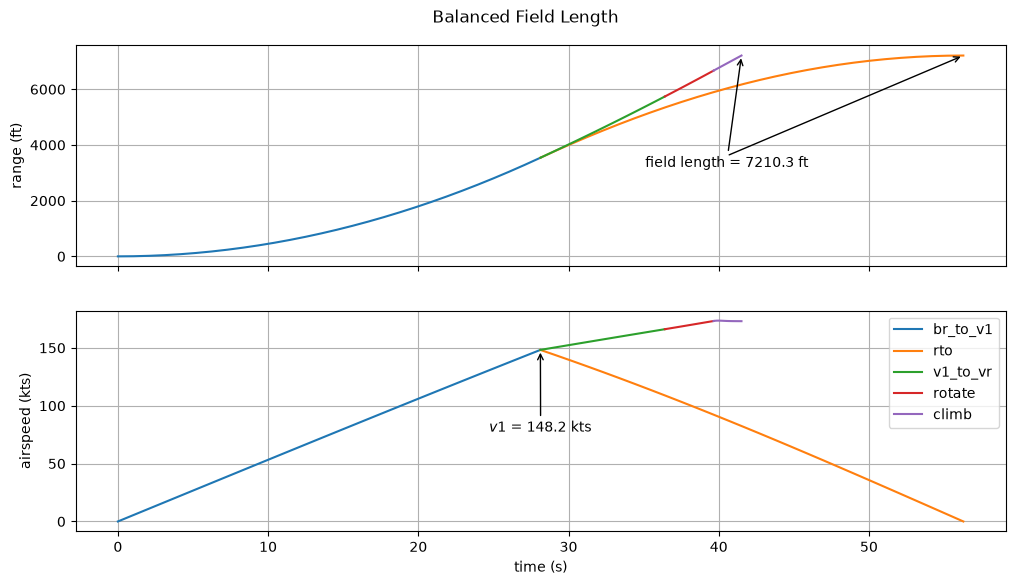

In [10]:
sim_prob = traj.sim_prob
sim_case = om.CaseReader(sim_prob.get_outputs_dir() / 'dymos_simulation.db').get_case('final')

fig, axes = plt.subplots(2, 1, sharex=True, gridspec_kw={'top': 0.92}, figsize=(12, 6))
for phase in ['br_to_v1', 'rto', 'v1_to_vr', 'rotate', 'climb']:
    r = sim_case.get_val(f'traj.{phase}.timeseries.r', units='ft')
    v = sim_case.get_val(f'traj.{phase}.timeseries.v', units='kn')
    t = sim_case.get_val(f'traj.{phase}.timeseries.time', units='s')
    axes[0].plot(t, r, '-', label=phase)
    axes[1].plot(t, v, '-', label=phase)
fig.suptitle('Balanced Field Length')
axes[1].set_xlabel('time (s)')
axes[0].set_ylabel('range (ft)')
axes[1].set_ylabel('airspeed (kts)')
axes[0].grid(True)
axes[1].grid(True)

tv1 = sim_case.get_val('traj.br_to_v1.timeseries.time', units='s')[-1, 0]
v1 = sim_case.get_val('traj.br_to_v1.timeseries.v', units='kn')[-1, 0]

tf_rto = sim_case.get_val('traj.rto.timeseries.time', units='s')[-1, 0]
rf_rto = sim_case.get_val('traj.rto.timeseries.r', units='ft')[-1, 0]

axes[0].annotate(f'field length = {r[-1, 0]:5.1f} ft', xy=(t[-1, 0], r[-1, 0]),
                 xycoords='data', xytext=(0.7, 0.5),
                 textcoords='axes fraction', arrowprops=dict(arrowstyle='->'),
                 horizontalalignment='center', verticalalignment='top')

axes[0].annotate('', xy=(tf_rto, rf_rto),
                 xycoords='data', xytext=(0.7, 0.5),
                 textcoords='axes fraction', arrowprops=dict(arrowstyle='->'),
                 horizontalalignment='center', verticalalignment='top')

axes[1].annotate(f'$v1$ = {v1:5.1f} kts', xy=(tv1, v1), xycoords='data', xytext=(0.5, 0.5),
                 textcoords='axes fraction', arrowprops=dict(arrowstyle='->'),
                 horizontalalignment='center', verticalalignment='top')

plt.legend()
plt.show()

In [11]:
from openmdao.utils.assert_utils import assert_near_equal

assert_near_equal(p.get_val('traj.rto.states:r')[-1], 2197.7, tolerance=0.01)

np.float64(6.171680930151498e-06)

## References

```{bibliography}
:filter: docname in docnames
```